# 04 - Parametre Ayarı ve Model Karşılaştırması (6. hafta)

Bu notebook'tan önce terminalde şu komutlar çalıştırılmış olmalı:

```powershell
python -m src.train            # varsayılan parametreler
python -m src.train --tune     # GridSearchCV ile ayarlı
python -m src.compare          # karşılaştırma tabloları ve grafikler
```

Bu notebook o çıktıları okur ve rapor için yorumlar. Hiçbir modeli yeniden eğitmez.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import config
from src.preprocess import read_gray
from src.train import REPORTS_DIR
from src.compare import family_change, KEYS

FIG = config.FIGURES_DIR
def resolve(p):
    p = Path(p)
    return p if p.is_absolute() else ROOT / p

## 1. Varsayılan ve ayarlı modeller

Asıl karşılaştırma ölçütü **makro F1**: 25 aileye eşit ağırlık verir.

In [2]:
kars = pd.read_csv(REPORTS_DIR / "karsilastirma.csv")
kars.drop(columns="parametreler")

,model,dogruluk_varsayilan,f1_makro_varsayilan,dogruluk_ayarli,f1_makro_ayarli,dogruluk_fark,f1_makro_fark
0,SVM (RBF),0.9513,0.8795,0.9850,0.9593,0.0337,0.0798
1,Random Forest,0.9845,0.9600,0.9829,0.9558,-0.0016,-0.0042
2,KNN,0.9797,0.9460,0.9807,0.9510,0.0010,0.0050


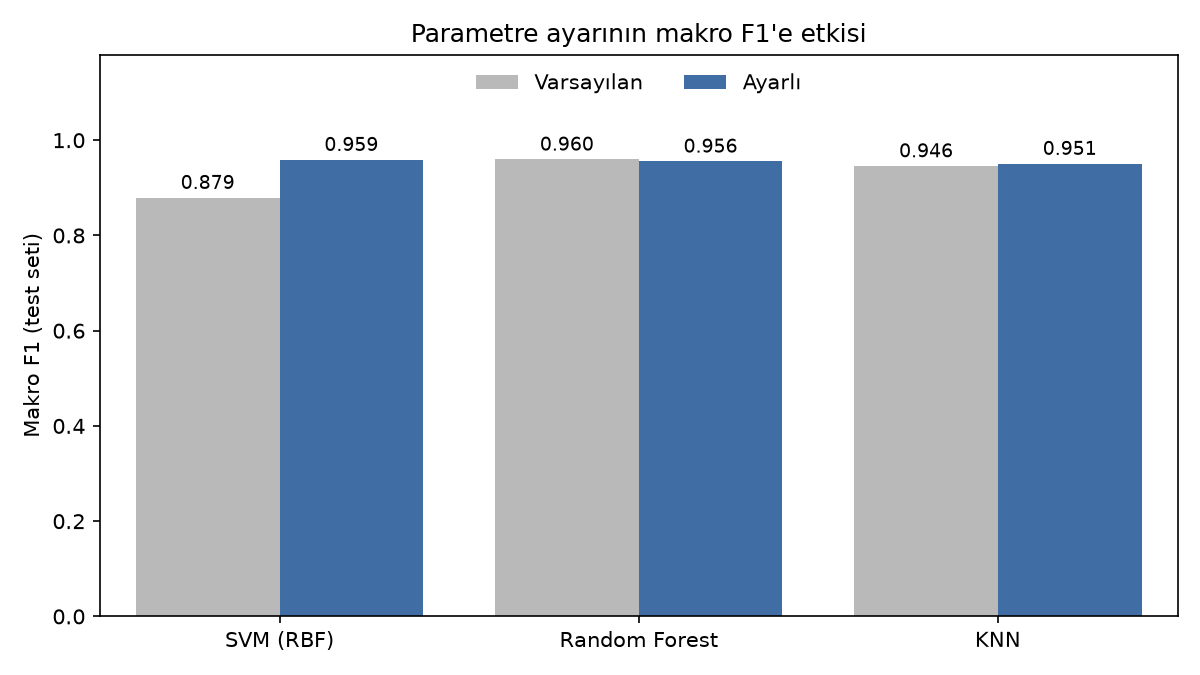

In [3]:
display(Image(FIG / "06_varsayilan_vs_ayarli.png", width=700))

## 2. Bulunan en iyi parametreler

Parametreler, **yalnızca eğitim seti** üzerinde 5 katlı çapraz doğrulamayla (StratifiedKFold) seçildi. Test seti bu seçimde hiç kullanılmadı.

In [4]:
for _, r in kars.iterrows():
    print(f"{r['model']:<14}", json.loads(r["parametreler"]))

SVM (RBF)      {'C': 1000, 'gamma': 0.1}
Random Forest  {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}
KNN            {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


## 3. Çapraz doğrulama ayrıntıları

Her model için en iyi 5 parametre kombinasyonu. `cv_f1_makro_std` küçükse sonuç kararlı demektir: 5 katın hepsinde benzer başarı alınmış.

In [5]:
for key in ["svm", "rf", "knn"]:
    p = REPORTS_DIR / f"cv_{key}.csv"
    if p.exists():
        cv = pd.read_csv(p)
        print(f"\n=== {key.upper()}: {len(cv)} kombinasyon denendi ===")
        display(cv.head(5).round(4))


=== SVM: 16 kombinasyon denendi ===


,C,gamma,cv_f1_makro_ort,cv_f1_makro_std,sira,egitim_suresi_sn
0,1000,0.1,0.9686,0.0018,1,1.2867
1,100,0.1,0.9685,0.0018,2,1.9653
2,10,0.1,0.9652,0.0043,3,1.8411
3,1000,0.01,0.9640,0.0027,4,0.6640
4,1000,scale,0.9633,0.0023,5,0.8253



=== RF: 18 kombinasyon denendi ===


,max_depth,min_samples_leaf,n_estimators,cv_f1_makro_ort,cv_f1_makro_std,sira,egitim_suresi_sn
0,20.0,1,100,0.9675,0.0045,1,6.2318
1,NaN,1,100,0.9673,0.0044,2,4.4499
2,40.0,1,100,0.9673,0.0044,2,5.5342
3,NaN,1,300,0.9671,0.0081,4,12.8915
4,40.0,1,300,0.9671,0.0081,4,16.0912



=== KNN: 20 kombinasyon denendi ===


,metric,n_neighbors,weights,cv_f1_makro_ort,cv_f1_makro_std,sira,egitim_suresi_sn
0,manhattan,5,distance,0.9625,0.0024,1,0.0697
1,manhattan,3,distance,0.9619,0.0035,2,0.0639
2,manhattan,3,uniform,0.9606,0.0036,3,0.0784
3,manhattan,7,distance,0.9602,0.0045,4,0.0667
4,manhattan,9,distance,0.9601,0.0056,5,0.0679


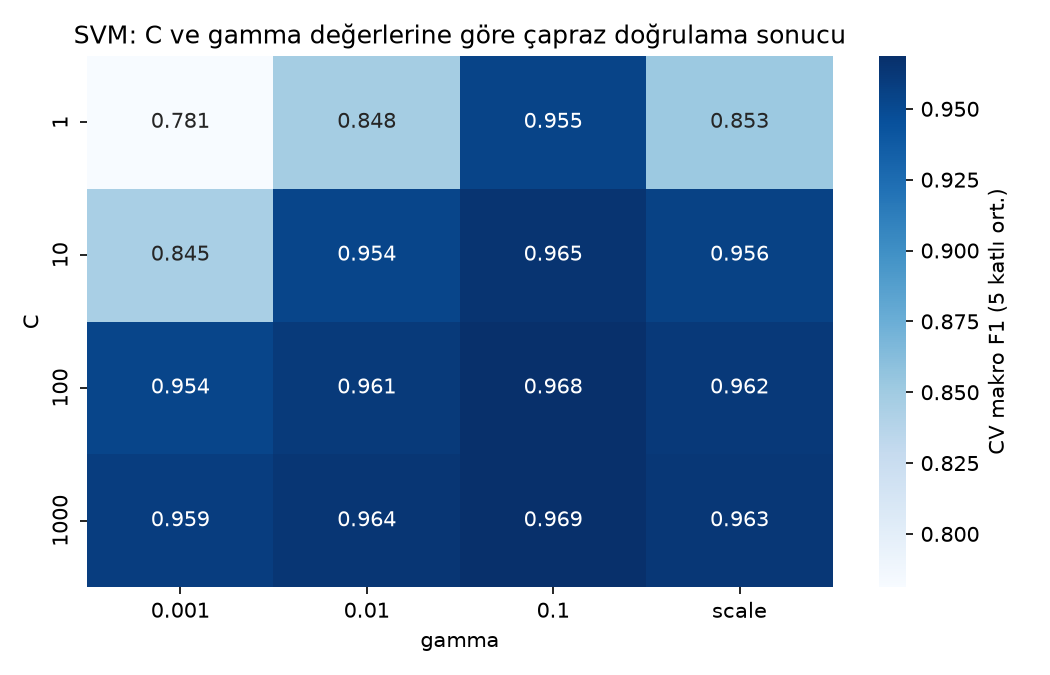

In [6]:
p = FIG / "06_svm_izgara.png"
if p.exists():
    display(Image(p, width=600))

**Okuma ipucu:** C büyüdükçe SVM eğitim verisine daha sıkı uyar. gamma büyüdükçe karar sınırı daha kıvrımlı olur. Isı haritasında en koyu hücre en iyi kombinasyon. Bir bölge düz ve aynı renkteyse model o aralıkta parametreye duyarsız demektir.

## 4. Aile bazında değişim (en iyi model)

En iyi ayarlı model: SVM (RBF) (makro F1 = 0.9593)


,aile,f1_varsayilan,ornek,f1_ayarli,fark
0,Swizzor.gen!E,0.6765,26,0.6000,-0.0765
13,Allaple.L,0.9984,318,1.0000,0.0016
19,Instantaccess,0.9942,86,1.0000,0.0058
10,Fakerean,0.9934,76,1.0000,0.0066
18,Lolyda.AA1,0.9885,43,1.0000,0.0115
15,Adialer.C,0.9796,24,1.0000,0.0204
8,Allaple.A,0.9730,590,0.9992,0.0262
17,Lolyda.AA2,0.9730,37,1.0000,0.0270
24,Yuner.A,0.9384,160,1.0000,0.0616
3,C2LOP.gen!g,0.8989,40,0.9639,0.0650


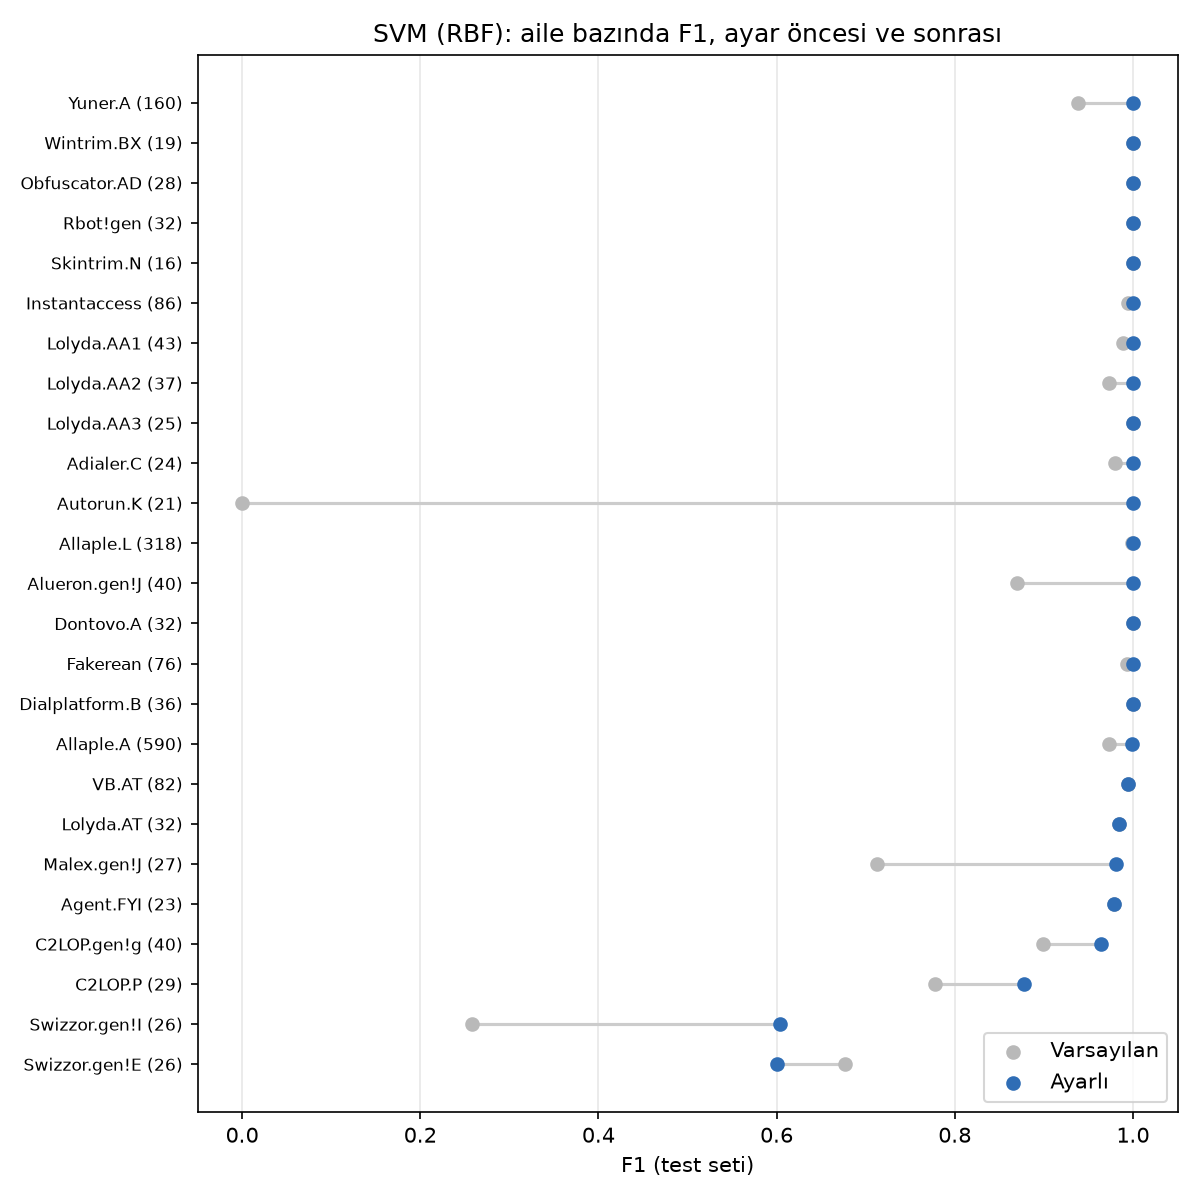

In [7]:
best = kars.sort_values("f1_makro_ayarli", ascending=False).iloc[0]
key = KEYS[best["model"]]
print("En iyi ayarlı model:", best["model"], f"(makro F1 = {best['f1_makro_ayarli']:.4f})")
fam = family_change(key)
display(fam[fam["fark"] != 0].sort_values("fark"))
display(Image(FIG / "06_aile_f1_degisim.png", width=650))

## 5. En çok karışan aile çiftleri

In [8]:
pairs = pd.read_csv(REPORTS_DIR / f"hatali_ciftler_{key}.csv")
pairs

,gercek_aile,tahmin_edilen,hata
0,Swizzor.gen!E,Swizzor.gen!I,10
1,Swizzor.gen!I,Swizzor.gen!E,9
2,C2LOP.P,C2LOP.gen!g,3
3,C2LOP.P,Swizzor.gen!I,1
4,Lolyda.AT,Agent.FYI,1
5,Swizzor.gen!E,C2LOP.P,1
6,Malex.gen!J,Allaple.A,1
7,Swizzor.gen!I,C2LOP.P,1
8,VB.AT,C2LOP.P,1


In [9]:
# Bütün modellerde (ayarlı) Swizzor ve C2LOP kaynaklı hata payı
for k in ["svm", "rf", "knn"]:
    p = REPORTS_DIR / f"tahminler_{k}_ayarli.csv"
    if not p.exists():
        continue
    t = pd.read_csv(p)
    wrong = t[t["family"] != t["tahmin"]]
    grp = wrong["family"].str.startswith(("Swizzor", "C2LOP"))
    print(f"{k.upper():<4} toplam hata: {len(wrong):>3}   Swizzor/C2LOP kaynaklı: {grp.sum():>3}"
          f"  (%{100 * grp.mean() if len(wrong) else 0:.0f})")

SVM  toplam hata:  28   Swizzor/C2LOP kaynaklı:  25  (%89)
RF   toplam hata:  32   Swizzor/C2LOP kaynaklı:  27  (%84)
KNN  toplam hata:  36   Swizzor/C2LOP kaynaklı:  28  (%78)


## 6. Swizzor.gen!E ve Swizzor.gen!I gerçekten benziyor mu?

İki aileden rastgele 6'şar görüntü, ardından ortalama görüntüleri ve aralarındaki fark. Ortalama fark çok küçükse, modelin bu iki aileyi karıştırması görsel olarak da açıklanmış olur.

In [10]:
idx = pd.read_csv(config.PROCESSED_DIR / "images_256" / "index.csv")
aileler = ["Swizzor.gen!E", "Swizzor.gen!I"]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, fam_name in enumerate(aileler):
    paths = idx[idx["family"] == fam_name]["path"].sample(6, random_state=config.RANDOM_STATE)
    for ax, p in zip(axes[row], paths):
        ax.imshow(read_gray(resolve(p)), cmap="gray", vmin=0, vmax=255)
        ax.axis("off")
    axes[row, 0].set_title(fam_name, loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "06_swizzor_ornekler.png", dpi=150)
plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_26744\2184560747.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [11]:
means = {f: np.mean([read_gray(resolve(p)).astype(float) for p in idx[idx["family"] == f]["path"]], axis=0)
         for f in aileler}
fark = np.abs(means[aileler[0]] - means[aileler[1]])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, f in zip(axes[:2], aileler):
    ax.imshow(means[f], cmap="gray", vmin=0, vmax=255); ax.set_title(f"{f} - ortalama"); ax.axis("off")
im = axes[2].imshow(fark, cmap="magma"); axes[2].set_title("Mutlak fark"); axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.savefig(FIG / "06_swizzor_ortalama_fark.png", dpi=150)
plt.show()
print(f"Ortalama piksel farkı: {fark.mean():.2f} / 255")

# Karşılaştırma için: iki ayrı aile arasındaki fark
ref = ["Allaple.A", "Yuner.A"]
m_ref = [np.mean([read_gray(resolve(p)).astype(float) for p in idx[idx["family"] == f]["path"].head(200)], axis=0) for f in ref]
print(f"Karşılaştırma ({ref[0]} vs {ref[1]}): {np.abs(m_ref[0] - m_ref[1]).mean():.2f} / 255")

C:\Users\Asus\AppData\Local\Temp\ipykernel_26744\1678727876.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Ortalama piksel farkı: 6.11 / 255
Karşılaştırma (Allaple.A vs Yuner.A): 39.01 / 255


## 7. Yanlış sınıflandırılan örnekler

En iyi modelin hata yaptığı ilk 8 test görüntüsü. Başlık: gerçek aile → tahmin.

In [12]:
t = pd.read_csv(REPORTS_DIR / f"tahminler_{key}_ayarli.csv")
wrong = t[t["family"] != t["tahmin"]].head(8)
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 3), squeeze=False)
    for ax, (_, r) in zip(axes[0], wrong.iterrows()):
        ax.imshow(read_gray(resolve(r["path"])), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{r['family']}\n→ {r['tahmin']}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIG / "06_hatali_ornekler.png", dpi=150)
    plt.show()
else:
    print("Hatalı tahmin yok.")

C:\Users\Asus\AppData\Local\Temp\ipykernel_26744\647075577.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 8. Notlar (rapora girecek)

- Parametre ayarı hangi modelde en çok fark yarattı? (Beklenti: SVM, çünkü varsayılan C=1 idi.)
- Ayarlı modellerde test sonucu çapraz doğrulama sonucuna yakın mı? Uzaksa neden olabilir?
- Ayardan sonra Swizzor ve C2LOP karışıklığı azaldı mı?
- Swizzor.gen!E ve gen!I'nin ortalama görüntü farkı, iki farklı ailenin farkıyla kıyaslandığında ne söylüyor?
- Sonuç: Raporda hangi model "en iyi" olarak sunulmalı? (Makro F1, süre ve kararlılık birlikte düşünülmeli.)